# Graph Autoencoder-Based Trust and Poisoning Detection

## Project flow
**MNIST → Federated Learning → Malicious Clients → Client Graph → Graph Autoencoder → Anomaly Score → Trust Score → Malicious-Client Detection**

This Google Colab notebook is an educational prototype. It simulates wireless edge devices as federated-learning clients.

In [1]:
from google.colab import files

uploaded = files.upload()
csv_filename = next(iter(uploaded))
print("Uploaded file:", csv_filename)

Saving GAE_Federated_Client_Dataset_50_Clients.csv to GAE_Federated_Client_Dataset_50_Clients.csv
Uploaded file: GAE_Federated_Client_Dataset_50_Clients.csv


In [2]:
!pip -q install scikit-learn pandas matplotlib

import copy
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
from sklearn.preprocessing import StandardScaler
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

# ============================================================
# Configuration
# ============================================================
SEED = 42
NUM_CLIENTS = 50
# Client IDs marked malicious in the 50-client CSV dataset.
# In Google Colab, upload GAE_Federated_Client_Dataset_50_Clients.csv
# when prompted by the data-loading cell below.
CLIENT_DATASET_PATH = Path("/content/GAE_Federated_Client_Dataset_50_Clients.csv")
MALICIOUS_CLIENTS = set()  # populated from CSV labels below
LOCAL_EPOCHS = 1
BATCH_SIZE = 64
LR = 0.01
FL_ROUNDS = 3
MAX_TRAIN_SAMPLES_PER_CLIENT = 600
GAE_EPOCHS = 500
GAE_LR = 0.01
TOP_K_NEIGHBORS = 3
ANOMALY_QUANTILE = 0.80

DATA_DIR = Path("data")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)




In [3]:
# ============================================================
# Load the 50-client labels from the provided CSV
# ============================================================
# If the CSV is not already at the path below, this cell asks you to upload it.
if not CLIENT_DATASET_PATH.exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        uploaded_csv = next((name for name in uploaded if name.lower().endswith(".csv")), None)
        if uploaded_csv is None:
            raise FileNotFoundError("Please upload the 50-client CSV file.")
        CLIENT_DATASET_PATH = Path("/content") / uploaded_csv
    except ImportError:
        raise FileNotFoundError(
            f"Place the 50-client CSV at: {CLIENT_DATASET_PATH.resolve()}"
        )

client_df = pd.read_csv(CLIENT_DATASET_PATH)
required_cols = {"client_id", "malicious_label"}
missing_cols = required_cols - set(client_df.columns)
if missing_cols:
    raise ValueError(f"CSV is missing required columns: {sorted(missing_cols)}")

client_df = client_df.sort_values("client_id").reset_index(drop=True)
if len(client_df) != NUM_CLIENTS:
    raise ValueError(
        f"Expected {NUM_CLIENTS} client records, but CSV contains {len(client_df)}. "
        "Please upload the 50-client dataset."
    )

if client_df["client_id"].nunique() != NUM_CLIENTS:
    raise ValueError("CSV must contain 50 unique client_id values.")

MALICIOUS_CLIENTS = set(
    client_df.loc[client_df["malicious_label"].astype(int) == 1, "client_id"].astype(int)
)
print(f"Loaded {len(client_df)} client records from CSV.")
print(f"Malicious clients from CSV labels: {sorted(MALICIOUS_CLIENTS)}")


Loaded 50 client records from CSV.
Malicious clients from CSV labels: [6, 8, 9, 16, 26, 27, 28, 29, 30, 34, 38, 42, 46, 50]


## 1. MNIST model


In [4]:
# ============================================================
# 1. Simple MNIST model
# ============================================================
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 8, 3, padding=1)
        self.conv2 = nn.Conv2d(8, 16, 3, padding=1)
        self.fc1 = nn.Linear(16 * 7 * 7, 32)
        self.fc2 = nn.Linear(32, 10)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.max_pool2d(x, 2)
        x = F.relu(self.conv2(x))
        x = F.max_pool2d(x, 2)
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)




## 2. Dataset and simulated FL clients


In [5]:
# ============================================================
# 2. Dataset and simulated FL clients
# ============================================================
def load_data():
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.1307,), (0.3081,))
    ])

    train = datasets.MNIST(DATA_DIR, train=True, download=True, transform=transform)
    test = datasets.MNIST(DATA_DIR, train=False, download=True, transform=transform)

    # Balanced random partition for a simple reproducible demo.
    indices = np.arange(len(train))
    rng = np.random.default_rng(SEED)
    rng.shuffle(indices)

    chunks = np.array_split(indices, NUM_CLIENTS)

    client_loaders = []
    for client_id, chunk in enumerate(chunks, start=1):
        # Keep runtime manageable.
        chunk = chunk[:MAX_TRAIN_SAMPLES_PER_CLIENT]
        subset = Subset(train, chunk.tolist())
        loader = DataLoader(subset, batch_size=BATCH_SIZE, shuffle=True)
        client_loaders.append(loader)

    test_loader = DataLoader(test, batch_size=256, shuffle=False)
    return client_loaders, test_loader




## 3. Federated learning and poisoning


In [6]:
# ============================================================
# 3. Malicious local training: targeted label flipping 1 -> 7
# ============================================================
def local_train(global_model, loader, malicious=False):
    model = copy.deepcopy(global_model).to(DEVICE)
    model.train()

    optimizer = torch.optim.SGD(model.parameters(), lr=LR)

    for _ in range(LOCAL_EPOCHS):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)

            if malicious:
                # Targeted label-flipping poisoning:
                # every source-class "1" is changed to target class "7".
                y = y.clone()
                y[y == 1] = 7

            optimizer.zero_grad()
            logits = model(x)
            loss = F.cross_entropy(logits, y)
            loss.backward()
            optimizer.step()

    return model.cpu()


def get_state_delta(global_model, local_model):
    delta = {}
    global_state = global_model.state_dict()
    local_state = local_model.state_dict()

    for name in global_state:
        delta[name] = local_state[name].float() - global_state[name].float()

    return delta


def flatten_delta(delta):
    parts = []
    for name in sorted(delta.keys()):
        parts.append(delta[name].reshape(-1))
    return torch.cat(parts).numpy()


def fedavg(global_model, local_models):
    global_state = global_model.state_dict()

    for key in global_state:
        stacked = torch.stack([m.state_dict()[key].float() for m in local_models])
        global_state[key] = stacked.mean(dim=0)

    global_model.load_state_dict(global_state)
    return global_model


@torch.no_grad()
def test_accuracy(model, loader):
    model = model.to(DEVICE)
    model.eval()

    correct = 0
    total = 0

    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        pred = model(x).argmax(dim=1)
        correct += (pred == y).sum().item()
        total += y.numel()

    model.cpu()
    return correct / total




## 4. Build graph node features


In [7]:
# ============================================================
# 4. Build compact node features from FL model updates
# ============================================================
def make_node_features(deltas):
    matrix = np.vstack(deltas)

    # Standardize before PCA.
    scaler = StandardScaler()
    matrix = scaler.fit_transform(matrix)

    # Keep enough dimensions for the graph model but avoid huge vectors.
    # SVD is used directly so no extra dependency is needed.
    _, _, vt = np.linalg.svd(matrix, full_matrices=False)
    k = min(8, matrix.shape[0] - 1, matrix.shape[1])
    components = vt[:k]
    reduced = matrix @ components.T

    return reduced.astype(np.float32)




## 5. Build client similarity graph


In [8]:
# ============================================================
# 5. Similarity graph
# ============================================================
def build_graph(node_features, top_k=TOP_K_NEIGHBORS):
    x = torch.tensor(node_features, dtype=torch.float32)

    # Cosine similarity.
    x_norm = F.normalize(x, p=2, dim=1)
    sim = x_norm @ x_norm.T
    sim.fill_diagonal_(0)

    n = x.size(0)
    adj = torch.zeros((n, n), dtype=torch.float32)

    for i in range(n):
        k = min(top_k, n - 1)
        values, indices = torch.topk(sim[i], k=k)
        for value, j in zip(values, indices):
            if value > 0:
                adj[i, j] = value

    # Make graph undirected.
    adj = torch.maximum(adj, adj.T)

    # Binary adjacency for reconstruction.
    binary_adj = (adj > 0).float()
    binary_adj.fill_diagonal_(0)

    return x, adj, binary_adj




## 6. Graph Autoencoder


In [9]:
# ============================================================
# 6. Simple Graph Autoencoder
# ============================================================
class GraphConv(nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()
        self.linear = nn.Linear(in_features, out_features)

    def forward(self, x, a_norm):
        return self.linear(a_norm @ x)


class GAEEncoder(nn.Module):
    def __init__(self, in_features, hidden=16, latent=8):
        super().__init__()
        self.gcn1 = GraphConv(in_features, hidden)
        self.gcn2 = GraphConv(hidden, latent)

    def forward(self, x, a_norm):
        h = F.relu(self.gcn1(x, a_norm))
        z = self.gcn2(h, a_norm)
        return z


class GraphAutoencoder(nn.Module):
    def __init__(self, in_features, hidden=16, latent=8):
        super().__init__()
        self.encoder = GAEEncoder(in_features, hidden, latent)
        self.feature_decoder = nn.Linear(latent, in_features)

    def forward(self, x, a_norm):
        z = self.encoder(x, a_norm)

        # Inner-product graph decoder.
        adj_logits = z @ z.T
        x_hat = self.feature_decoder(z)

        return z, adj_logits, x_hat


def normalize_adjacency(adj):
    n = adj.size(0)
    a = adj + torch.eye(n)
    degree = a.sum(dim=1)
    d_inv_sqrt = torch.diag(torch.pow(degree.clamp(min=1e-8), -0.5))
    return d_inv_sqrt @ a @ d_inv_sqrt


def train_gae(x, adj):
    a_norm = normalize_adjacency(adj).to(DEVICE)
    x = x.to(DEVICE)

    model = GraphAutoencoder(x.size(1)).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=GAE_LR)

    # Positive class is sparse, so use a weighted BCE.
    positive = adj.sum().item()
    total = adj.numel()
    pos_weight = (total - positive) / max(positive, 1.0)
    pos_weight = torch.tensor([pos_weight], device=DEVICE)

    for epoch in range(GAE_EPOCHS):
        model.train()
        optimizer.zero_grad()

        z, adj_logits, x_hat = model(x, a_norm)

        adj_loss = F.binary_cross_entropy_with_logits(
            adj_logits,
            adj.to(DEVICE),
            pos_weight=pos_weight
        )
        feature_loss = F.mse_loss(x_hat, x)

        loss = adj_loss + 0.5 * feature_loss
        loss.backward()
        optimizer.step()

    return model, a_norm


@torch.no_grad()
def anomaly_scores(model, x, adj, a_norm):
    model.eval()

    x = x.to(DEVICE)
    adj = adj.to(DEVICE)
    a_norm = a_norm.to(DEVICE)

    z, adj_logits, x_hat = model(x, a_norm)

    # Feature reconstruction error.
    feature_error = ((x_hat - x) ** 2).mean(dim=1)

    # Each node's row reconstruction error.
    adj_prob = torch.sigmoid(adj_logits)
    edge_error = ((adj_prob - adj) ** 2).mean(dim=1)

    # Combine both signals.
    score = feature_error + edge_error

    return (
        score.cpu().numpy(),
        feature_error.cpu().numpy(),
        edge_error.cpu().numpy(),
        z.cpu().numpy()
    )




## 7. Detection and evaluation


In [10]:
# ============================================================
# 7. Detection threshold and evaluation
# ============================================================
def evaluate_detection(scores, true_labels):
    threshold = float(np.quantile(scores, ANOMALY_QUANTILE))
    predictions = (scores >= threshold).astype(int)

    acc = accuracy_score(true_labels, predictions)
    precision = precision_score(true_labels, predictions, zero_division=0)
    recall = recall_score(true_labels, predictions, zero_division=0)
    f1 = f1_score(true_labels, predictions, zero_division=0)

    return threshold, predictions, acc, precision, recall, f1


def save_results(scores, feature_error, edge_error, true_labels, predictions):
    # Convert anomaly score into an illustrative trust score.
    # Higher anomaly -> lower trust.
    max_score = max(float(scores.max()), 1e-8)
    trust = 1.0 - np.clip(scores / max_score, 0, 1)

    df = pd.DataFrame({
        "client_id": np.arange(1, NUM_CLIENTS + 1),
        "true_malicious": true_labels,
        "anomaly_score": scores,
        "feature_reconstruction_error": feature_error,
        "graph_reconstruction_error": edge_error,
        "trust_score": trust,
        "predicted_malicious": predictions
    })

    path = OUTPUT_DIR / "client_results.csv"
    df.to_csv(path, index=False)
    return df


def plot_scores(df, threshold):
    plt.figure(figsize=(10, 5))
    plt.bar(df["client_id"], df["anomaly_score"])
    plt.axhline(threshold, linestyle="--", label=f"Detection threshold = {threshold:.4f}")
    plt.xlabel("Client ID")
    plt.ylabel("Anomaly score")
    plt.title("GAE-Based Client Anomaly Detection")
    plt.xticks(df["client_id"])
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "anomaly_scores.png", dpi=150)
    plt.close()


def plot_accuracy(history):
    plt.figure(figsize=(7, 4))
    plt.plot(range(1, len(history) + 1), history, marker="o")
    plt.xlabel("Federated round")
    plt.ylabel("Global test accuracy")
    plt.title("Federated Learning Global Accuracy")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "training_accuracy.png", dpi=150)
    plt.close()




def plot_trust_scores(df):
    """Plot trust score for every client; lower trust indicates more suspicion."""
    plt.figure(figsize=(12, 5))
    bars = plt.bar(df["client_id"], df["trust_score"])
    for bar, malicious in zip(bars, df["true_malicious"]):
        if malicious == 1:
            bar.set_hatch("//")
    plt.xlabel("Client ID")
    plt.ylabel("Trust score (0 = low, 1 = high)")
    plt.title("GAE-Based Client Trust Scores")
    plt.xticks(df["client_id"], rotation=90)
    plt.ylim(0, 1.05)
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "trust_scores.png", dpi=180)
    plt.show()
    plt.close()


def plot_detection_metrics(acc, precision, recall, f1):
    """Plot measured detection metrics from the run."""
    names = ["Accuracy", "Precision", "Recall", "F1-score"]
    values = [acc, precision, recall, f1]
    plt.figure(figsize=(8, 5))
    bars = plt.bar(names, values)
    plt.ylabel("Score")
    plt.title("Poisoning Detection Performance")
    plt.ylim(0, 1.05)
    plt.grid(axis="y", alpha=0.25)
    for bar, value in zip(bars, values):
        plt.text(bar.get_x() + bar.get_width()/2, value + 0.02,
                 f"{value:.3f}", ha="center", va="bottom")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "detection_metrics.png", dpi=180)
    plt.show()
    plt.close()


def plot_confusion_matrix(true_labels, predictions):
    """Plot confusion matrix for normal vs malicious client detection."""
    from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
    cm = confusion_matrix(true_labels, predictions, labels=[0, 1])
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Normal", "Malicious"]
    )
    disp.plot(values_format="d")
    plt.title("Client Poisoning Detection Confusion Matrix")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=180)
    plt.show()
    plt.close()


def plot_score_comparison(df):
    """Compare anomaly and trust scores, grouped by ground-truth client type."""
    benign = df.loc[df["true_malicious"] == 0, "anomaly_score"]
    malicious = df.loc[df["true_malicious"] == 1, "anomaly_score"]
    benign_trust = df.loc[df["true_malicious"] == 0, "trust_score"]
    malicious_trust = df.loc[df["true_malicious"] == 1, "trust_score"]

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    axes[0].boxplot([benign, malicious], labels=["Normal", "Malicious"])
    axes[0].set_title("Anomaly Score by Client Type")
    axes[0].set_ylabel("Anomaly score")
    axes[0].grid(axis="y", alpha=0.25)

    axes[1].boxplot([benign_trust, malicious_trust], labels=["Normal", "Malicious"])
    axes[1].set_title("Trust Score by Client Type")
    axes[1].set_ylabel("Trust score")
    axes[1].grid(axis="y", alpha=0.25)

    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "score_comparison.png", dpi=180)
    plt.show()
    plt.close(fig)


## 8. Run the complete experiment


GAE-BASED TRUST AND POISONING DETECTION
Device: cpu
Clients: 50
Malicious clients: [6, 8, 9, 16, 26, 27, 28, 29, 30, 34, 38, 42, 46, 50]



100%|██████████| 9.91M/9.91M [00:01<00:00, 5.83MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 152kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.45MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.0MB/s]



Federated round 1/3
  Client 01: BENIGN
  Client 02: BENIGN
  Client 03: BENIGN
  Client 04: BENIGN
  Client 05: BENIGN
  Client 06: MALICIOUS
  Client 07: BENIGN
  Client 08: MALICIOUS
  Client 09: MALICIOUS
  Client 10: BENIGN
  Client 11: BENIGN
  Client 12: BENIGN
  Client 13: BENIGN
  Client 14: BENIGN
  Client 15: BENIGN
  Client 16: MALICIOUS
  Client 17: BENIGN
  Client 18: BENIGN
  Client 19: BENIGN
  Client 20: BENIGN
  Client 21: BENIGN
  Client 22: BENIGN
  Client 23: BENIGN
  Client 24: BENIGN
  Client 25: BENIGN
  Client 26: MALICIOUS
  Client 27: MALICIOUS
  Client 28: MALICIOUS
  Client 29: MALICIOUS
  Client 30: MALICIOUS
  Client 31: BENIGN
  Client 32: BENIGN
  Client 33: BENIGN
  Client 34: MALICIOUS
  Client 35: BENIGN
  Client 36: BENIGN
  Client 37: BENIGN
  Client 38: MALICIOUS
  Client 39: BENIGN
  Client 40: BENIGN
  Client 41: BENIGN
  Client 42: MALICIOUS
  Client 43: BENIGN
  Client 44: BENIGN
  Client 45: BENIGN
  Client 46: MALICIOUS
  Client 47: BENIGN


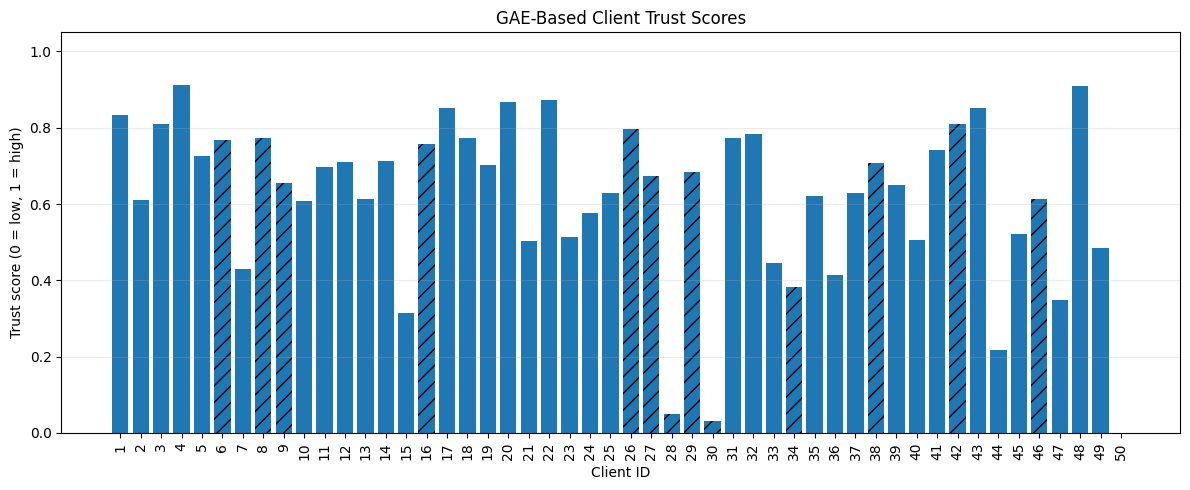

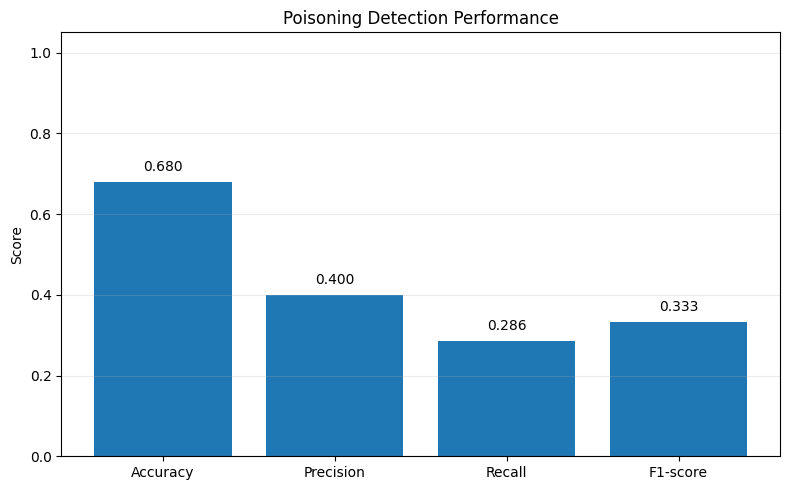

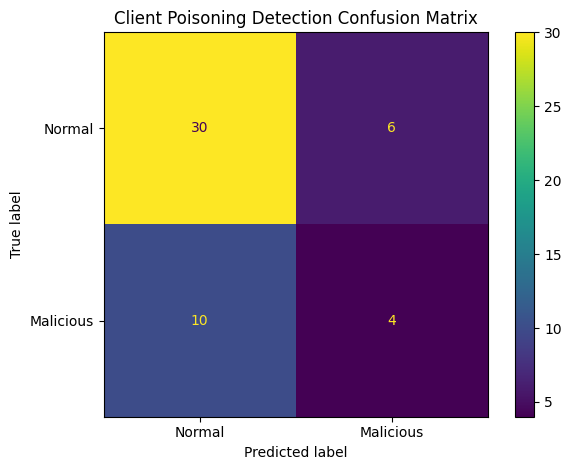

/tmp/ipykernel_7356/1075908642.py:127: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot([benign, malicious], labels=["Normal", "Malicious"])
/tmp/ipykernel_7356/1075908642.py:132: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([benign_trust, malicious_trust], labels=["Normal", "Malicious"])


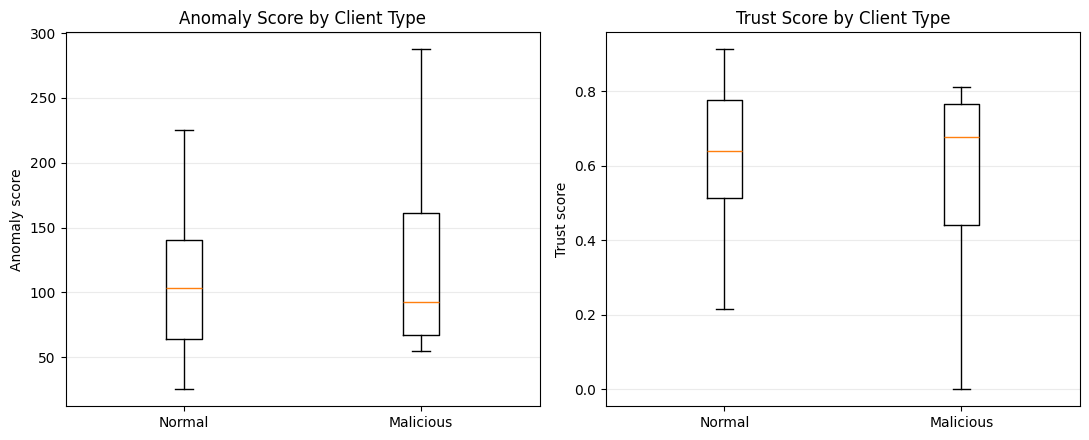


CLIENT DETECTION RESULTS
 client_id  anomaly_score  trust_score  true_malicious  predicted_malicious     status
         1      47.814075     0.833696               0                    0     NORMAL
         2     111.716614     0.611434               0                    0     NORMAL
         3      55.034752     0.808582               0                    0     NORMAL
         4      25.208088     0.912323               0                    0     NORMAL
         5      79.001678     0.725221               0                    0     NORMAL
         6      66.641945     0.768210               1                    0     NORMAL
         7     163.669983     0.430733               0                    1 SUSPICIOUS
         8      65.575020     0.771921               1                    0     NORMAL
         9      99.078903     0.655390               1                    0     NORMAL
        10     112.930107     0.607214               0                    0     NORMAL
        11      8

In [11]:
set_seed()

print("=" * 65)
print("GAE-BASED TRUST AND POISONING DETECTION")
print("=" * 65)
print(f"Device: {DEVICE}")
print(f"Clients: {NUM_CLIENTS}")
print(f"Malicious clients: {sorted(MALICIOUS_CLIENTS)}")
print()

client_loaders, test_loader = load_data()

global_model = SmallCNN()
accuracy_history = []

# Store latest round model updates for graph construction.
latest_deltas = [None] * NUM_CLIENTS

for rnd in range(1, FL_ROUNDS + 1):
    print(f"\nFederated round {rnd}/{FL_ROUNDS}")

    local_models = []

    for i, loader in enumerate(client_loaders, start=1):
        malicious = i in MALICIOUS_CLIENTS

        local_model = local_train(
            global_model,
            loader,
            malicious=malicious
        )

        delta = get_state_delta(global_model, local_model)
        latest_deltas[i - 1] = flatten_delta(delta)
        local_models.append(local_model)

        status = "MALICIOUS" if malicious else "BENIGN"
        print(f"  Client {i:02d}: {status}")

    global_model = fedavg(global_model, local_models)

    acc = test_accuracy(global_model, test_loader)
    accuracy_history.append(acc)
    print(f"  Global test accuracy: {acc:.4f}")

# --------------------------------------------------------
# Graph construction
# --------------------------------------------------------
print("\nBuilding client graph...")
node_features_np = make_node_features(latest_deltas)
x, weighted_adj, binary_adj = build_graph(node_features_np)

print("Node feature shape:", tuple(x.shape))
print("Graph edges:", int(binary_adj.sum().item() / 2))

# --------------------------------------------------------
# Train GAE
# --------------------------------------------------------
print(f"\nTraining Graph Autoencoder for {GAE_EPOCHS} epochs...")
gae, a_norm = train_gae(x, binary_adj)

scores, feature_error, edge_error, embeddings = anomaly_scores(
    gae, x, binary_adj, a_norm
)

true_labels = np.array([
    1 if (i + 1) in MALICIOUS_CLIENTS else 0
    for i in range(NUM_CLIENTS)
])

threshold, predictions, acc, precision, recall, f1 = evaluate_detection(
    scores,
    true_labels
)

df = save_results(
    scores,
    feature_error,
    edge_error,
    true_labels,
    predictions
)

plot_scores(df, threshold)
plot_accuracy(accuracy_history)
plot_trust_scores(df)
plot_detection_metrics(acc, precision, recall, f1)
plot_confusion_matrix(true_labels, predictions)
plot_score_comparison(df)

# --------------------------------------------------------
# Print final results
# --------------------------------------------------------
print("\n" + "=" * 65)
print("CLIENT DETECTION RESULTS")
print("=" * 65)

display_df = df.copy()
display_df["status"] = np.where(
    display_df["predicted_malicious"] == 1,
    "SUSPICIOUS",
    "NORMAL"
)

print(
    display_df[
        ["client_id", "anomaly_score", "trust_score",
         "true_malicious", "predicted_malicious", "status"]
    ].to_string(index=False)
)

print("\nDetection metrics")
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

detected = display_df.loc[
    display_df["predicted_malicious"] == 1,
    "client_id"
].tolist()

print("\nActual malicious clients:", sorted(MALICIOUS_CLIENTS))
print("Detected suspicious clients:", detected)

print("\nFiles saved:")
print("  outputs/client_results.csv")
print("  outputs/anomaly_scores.png")
print("  outputs/training_accuracy.png")
print("  outputs/trust_scores.png")
print("  outputs/detection_metrics.png")
print("  outputs/confusion_matrix.png")
print("  outputs/score_comparison.png")

print("\nNote:")
print("The threshold is automatically chosen from the 80th percentile")
print("for this small demonstration. For a research evaluation, use")
print("a validation set or a threshold learned without attack labels.")

## How to explain the result

A client with unusually high reconstruction/anomaly error is flagged as suspicious. The notebook compares the predicted suspicious clients with the two simulated malicious clients and reports accuracy, precision, recall and F1-score. The malicious clients are deliberately simulated using label flipping, so this is a demonstration rather than a real-world security deployment.